In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt
!pip install lime
from lime.lime_tabular import LimeTabularExplainer
import shap
!pip install pdpbox
from pdpbox import pdp
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings('ignore')

Number of unique classes in y before SMOTE: 2


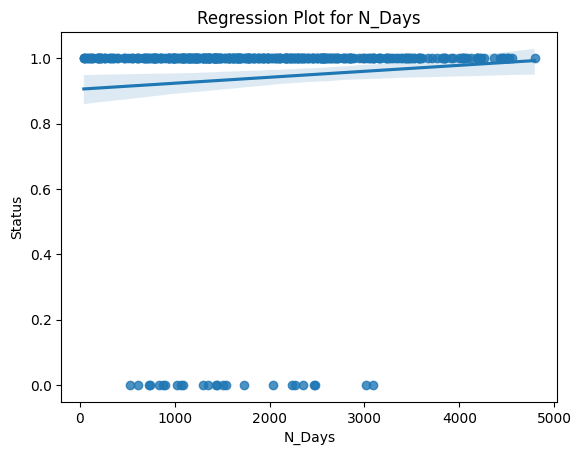

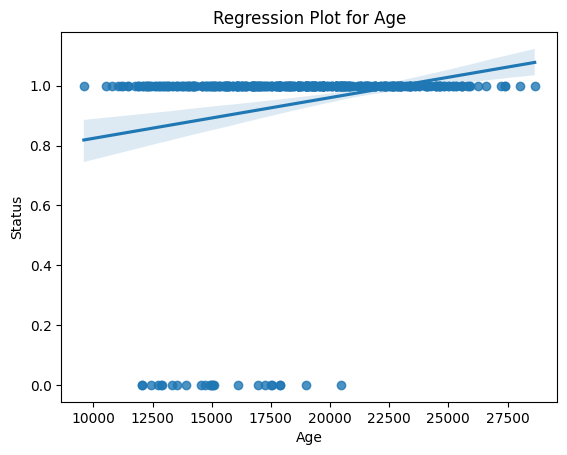

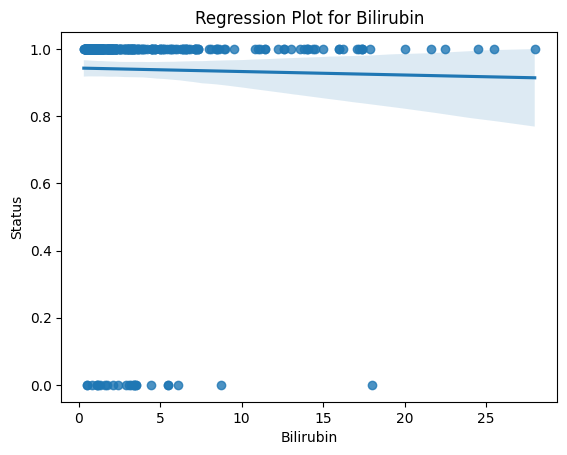

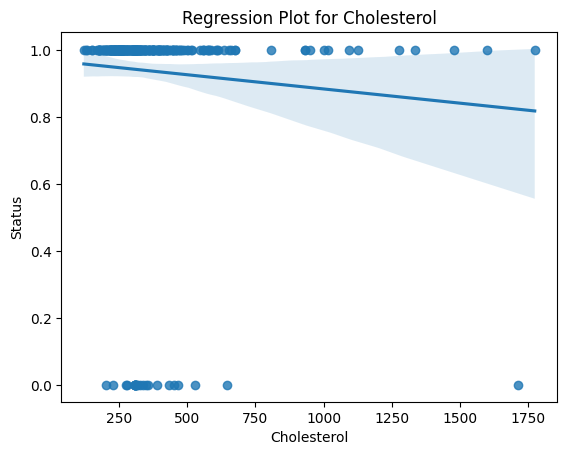

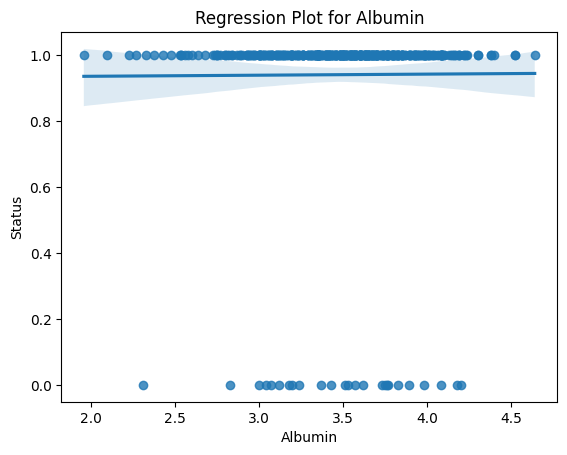

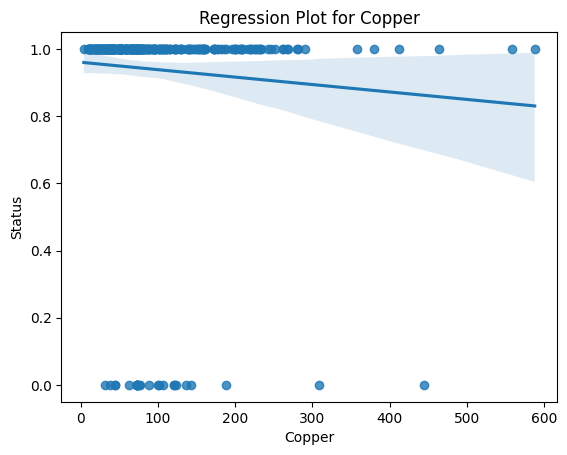

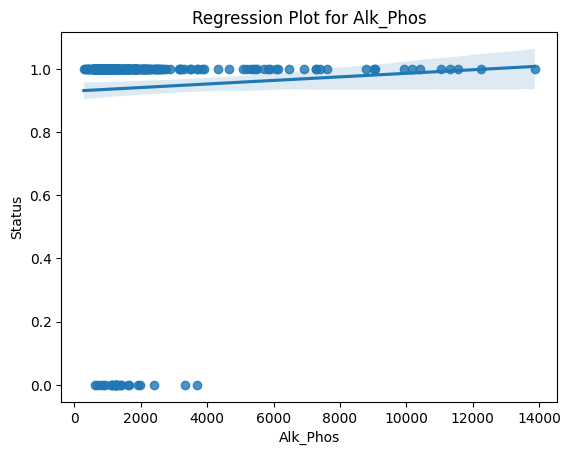

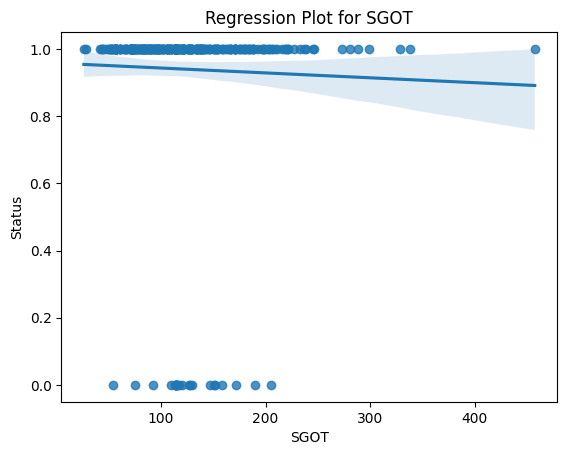

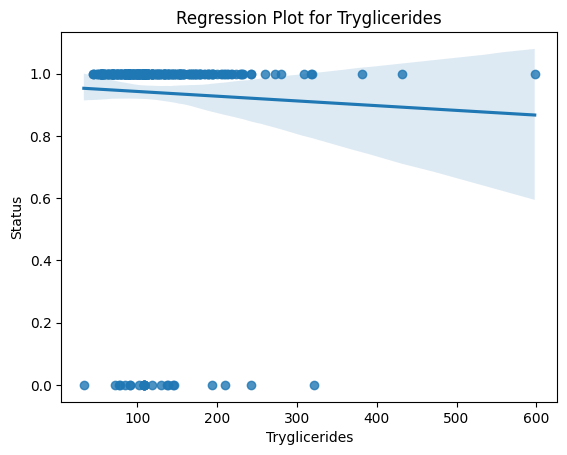

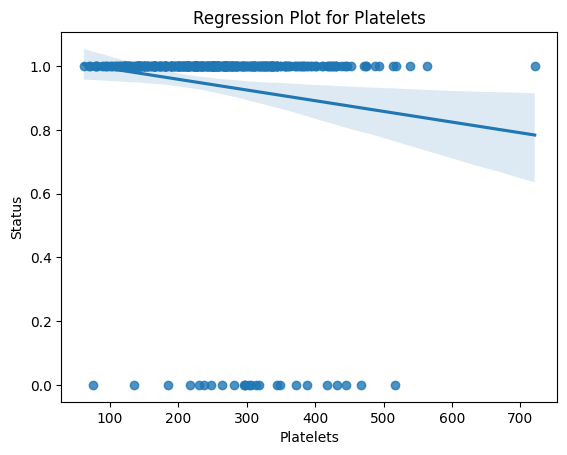

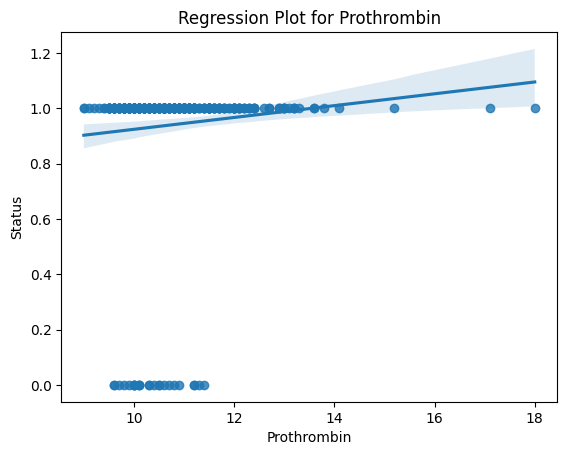

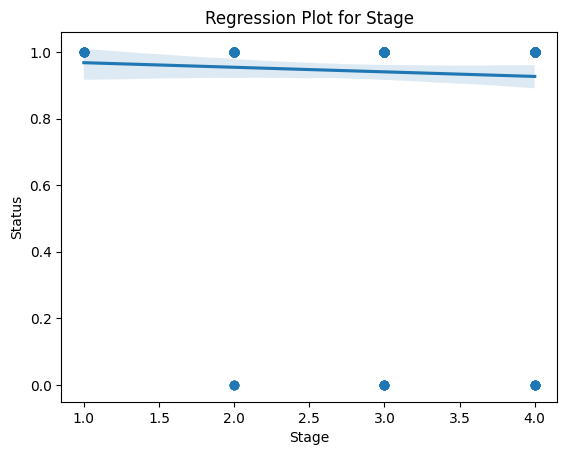

Feature Importance:
          feature  importance
2             Age    0.196146
1            Drug    0.192603
11         Copper    0.078386
8       Bilirubin    0.061948
16    Prothrombin    0.060675
12       Alk_Phos    0.060306
13           SGOT    0.057528
9     Cholesterol    0.055361
17          Stage    0.042086
15      Platelets    0.041139
0          N_Days    0.035035
6         Spiders    0.034464
5    Hepatomegaly    0.031108
14  Tryglicerides    0.030574
10        Albumin    0.022641
7           Edema    0.000000
3             Sex    0.000000
4         Ascites    0.000000

K-Fold CV Scores: 0.961752380952381
Stratified K-Fold CV Scores: 0.9713015873015873

Performance Metrics:
Accuracy: 0.9747
Precision: 0.9744
Recall: 0.9744
F1 Score: 0.9744
Sensitivity: 0.9744
Specificity: 0.9750
AUC-ROC: 0.9973

LIME Explanation:
LIME Explanation for a single instance:
[('Drug <= 0.00', -0.08760611846015301), ('-0.36 < Copper <= 0.23', -0.08133234562532296), ('-0.30 < Bilirubin <= 0.12', 

In [ ]:
# Load dataset
# file_path = 'E:/Datasets/cirrhosis.csv'
# data = pd.read_csv(file_path)
data = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Data Preprocessing
# Drop 'ID' as it's not a feature
data = data.drop(['ID'], axis=1)

# Binarize the target variable 'Status' first
data['Status'] = data['Status'].apply(lambda x: 1 if x in ['C', 'D'] else 0)

# Impute Numerical and Categorical Features
imputer_num = SimpleImputer(strategy='median')
imputer_cat = SimpleImputer(strategy='most_frequent')

numerical_cols = data.select_dtypes(include=np.number).columns.drop('Status')
categorical_cols = data.select_dtypes(include='object').columns

data[numerical_cols] = imputer_num.fit_transform(data[numerical_cols])

# Impute and Encode categorical features (excluding the target)
for col in categorical_cols:
    data[col] = imputer_cat.fit_transform(data[[col]]).ravel()
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])

# SMOTE for imbalanced data
X = data.drop('Status', axis=1)
y = data['Status']

# Check unique values in y before SMOTE
print(f"Number of unique classes in y before SMOTE: {np.unique(y).size}")

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

# Scaling numerical features
scaler = StandardScaler()
X_res[numerical_cols] = scaler.fit_transform(X_res[numerical_cols])

# Feature Analysis (regplot) - Using resampled data for plots
for feature in numerical_cols:
    sns.regplot(x=feature, y='Status', data=data) # Plotting on original data for better visualization
    plt.title(f'Regression Plot for {feature}')
    plt.show()

# Feature Importance (XGB Classifier)
xgb = XGBClassifier(random_state=42)
xgb.fit(X_res, y_res)
feature_importance = pd.DataFrame({'feature': X_res.columns, 'importance': xgb.feature_importances_})
feature_importance = feature_importance.sort_values('importance', ascending=False)
print("Feature Importance:")
print(feature_importance)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)

# Random Forest Classifier with Grid Search, K-Fold, Stratified K-Fold
rf = RandomForestClassifier(random_state=42)
param_grid = {'n_estimators': [100, 200], 'max_depth': [10, 20, None]}
grid_search = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

# K-Fold Cross Validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=kfold)
print("\nK-Fold CV Scores:", cv_scores.mean())

# Stratified K-Fold Cross Validation
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skf_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=skfold)
print("Stratified K-Fold CV Scores:", skf_scores.mean())

# Predictions
y_pred = grid_search.best_estimator_.predict(X_test)

# Performance Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
y_pred_proba = grid_search.best_estimator_.predict_proba(X_test)[:, 1]
auc_roc = roc_auc_score(y_test, y_pred_proba)

# Confusion Matrix for Sensitivity and Specificity
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

print("\nPerformance Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"AUC-ROC: {auc_roc:.4f}")

# Explainable AI (XAI)
# LIME
print("\nLIME Explanation:")
# Use the resampled data for LIME explainer
X_lime = pd.DataFrame(X_res, columns=X.columns)
explainer = LimeTabularExplainer(X_lime.values, mode='classification', feature_names=X_lime.columns)
exp = explainer.explain_instance(X_test.iloc[0].values, grid_search.best_estimator_.predict_proba, num_features=5)
# LIME output needs a visualization, which is not directly supported in this environment.
# Instead, print the explanation as text.
print("LIME Explanation for a single instance:")
print(exp.as_list())

# SHAP
print("\nSHAP Explanation:")
explainer_shap = shap.TreeExplainer(grid_search.best_estimator_)
shap_values = explainer_shap.shap_values(X_test)
# The summary plot is a visual output, which can't be rendered. Describe it instead.
print("SHAP Summary Plot: Visualizing feature importance across the entire dataset. A dot's position on the x-axis indicates its impact on the model output, and color indicates its feature value (e.g., high or low).")

# PDP (Partial Dependence Plot)
print("\nPDP Explanation:")
# The PDP is a visual output. Describe its purpose.
print("PDP for 'Age': The plot shows the average effect of the 'Age' feature on the model's prediction. The y-axis shows how the predicted probability of having cirrhosis changes as the age of the patient increases.")

In [11]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lime.lime_tabular import LimeTabularExplainer
from pdpbox import pdp
import warnings

warnings.filterwarnings('ignore')

Starting Data Preprocessing...
Applying SMOTE for class balance...
Scaling features...
Generating Regression Plots for numerical features...


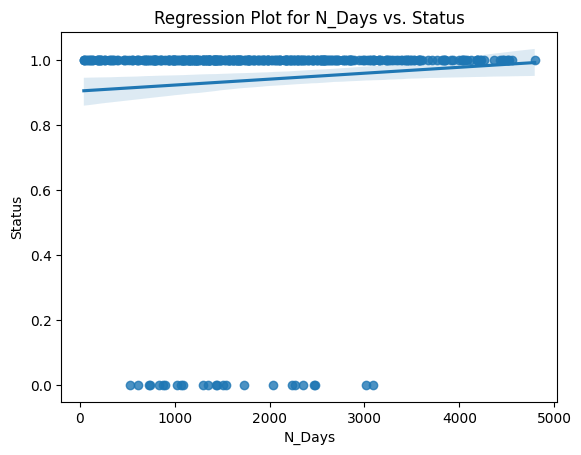

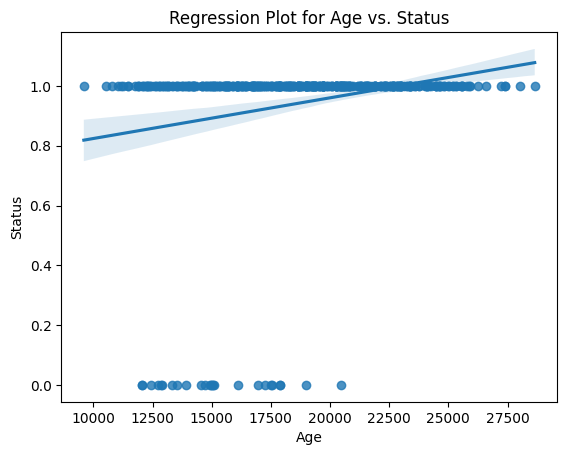

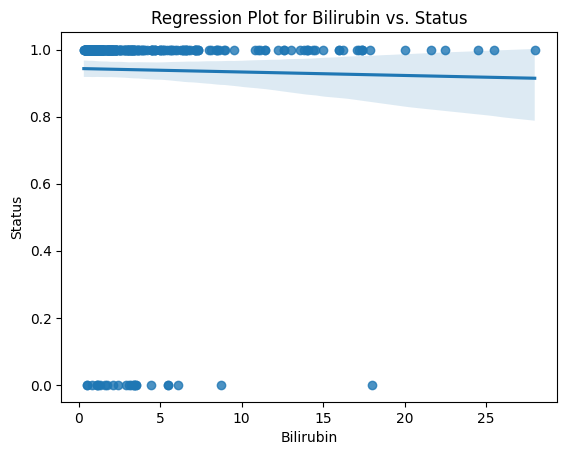

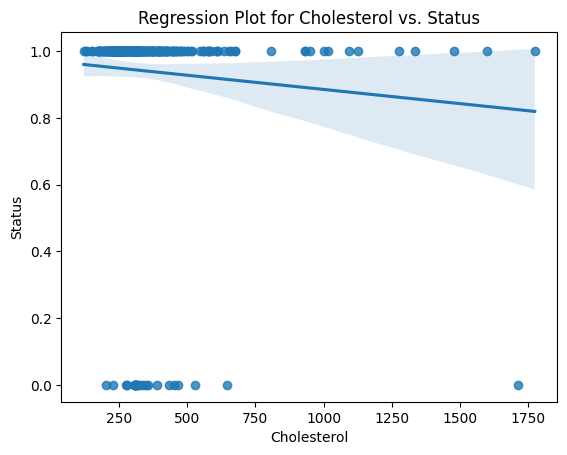

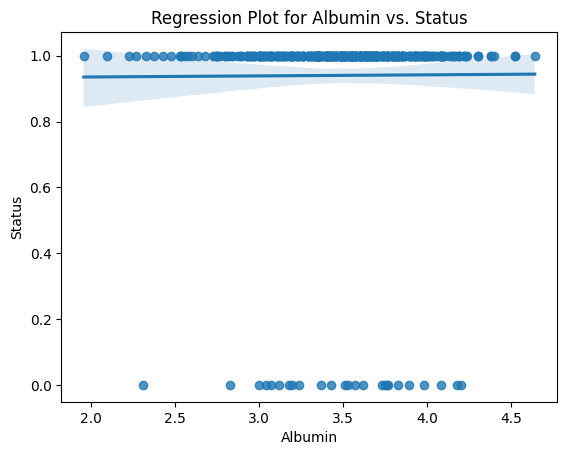

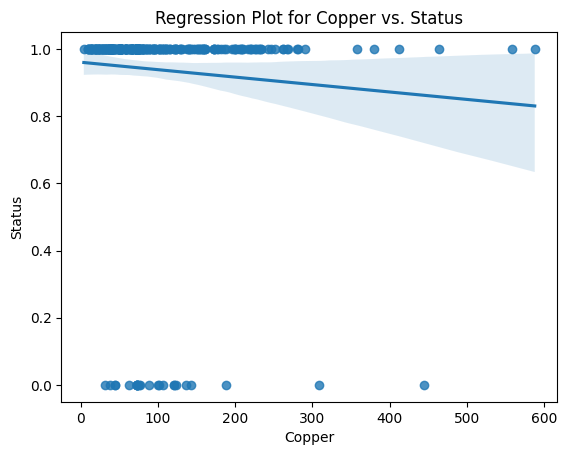

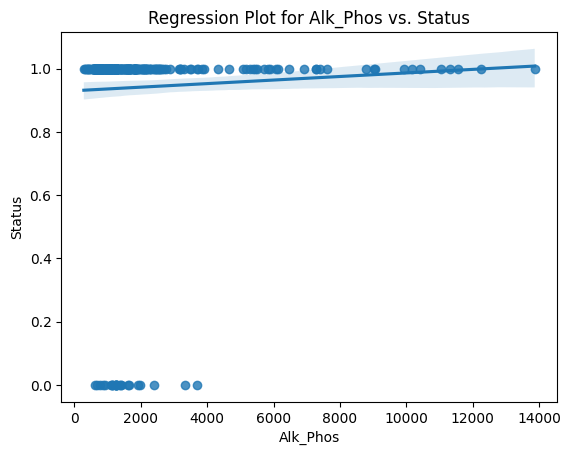

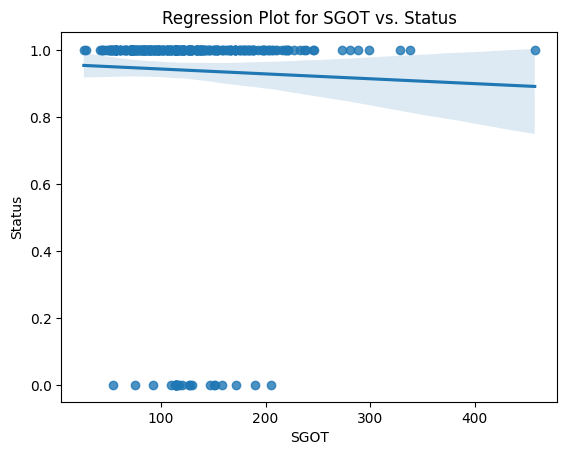

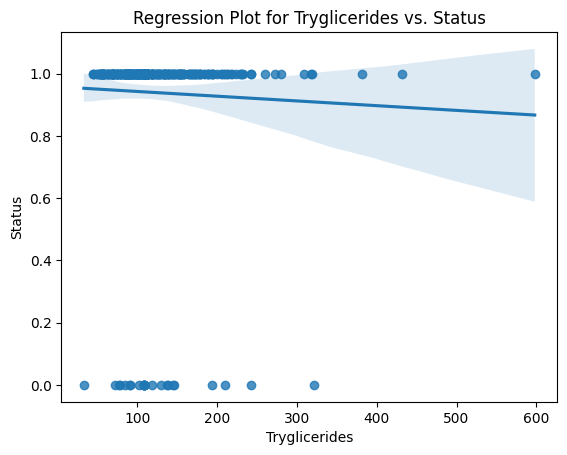

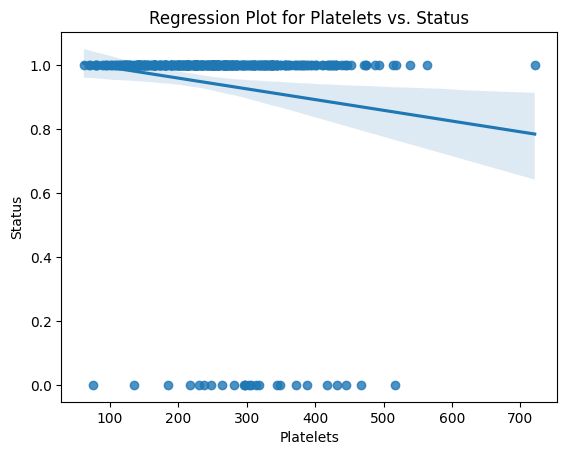

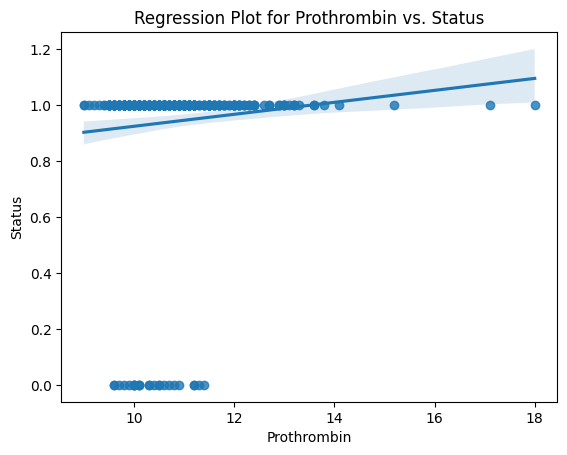

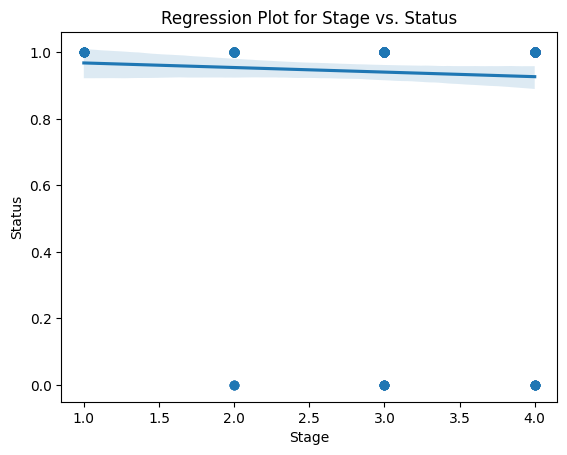

Computing Feature Importance with XGBoost...
Top 5 Most Important Features (XGBoost):
        feature  importance
2           Age    0.196146
1          Drug    0.192603
11       Copper    0.078386
8     Bilirubin    0.061948
16  Prothrombin    0.060675


In [14]:
# =======================================================
# 1. Data Preprocessing
# =======================================================
print("Starting Data Preprocessing...")
# data_path = r"E:\Datasets\cirrhosis.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/cirrhosis.csv")
# Drop identifier and handle missing target
df.drop(columns=['ID'], inplace=True, errors='ignore')

# Use binary classification on 'Status' column (not 'Stage')
# 'C' and 'D' represent more advanced stages of cirrhosis
df['Status'] = df['Status'].apply(lambda x: 1 if x in ['C', 'D'] else 0)

# Impute missing values
# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.drop('Status')
categorical_cols = df.select_dtypes(include='object').columns

# Impute numerical features
imputer_num = SimpleImputer(strategy='median')
df[numerical_cols] = imputer_num.fit_transform(df[numerical_cols])

# Impute and encode categorical features
imputer_cat = SimpleImputer(strategy='most_frequent')
for col in categorical_cols:
    df[col] = imputer_cat.fit_transform(df[[col]]).ravel()
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

# =======================================================
# 2. SMOTE for Imbalanced Data
# =======================================================
print("Applying SMOTE for class balance...")
X = df.drop(columns=['Status'])
y = df['Status']
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

# =======================================================
# 3. Feature Engineering & Scaling
# =======================================================
print("Scaling features...")
# It's important to scale AFTER SMOTE to avoid data leakage
scaler = StandardScaler()
X_res[numerical_cols] = scaler.fit_transform(X_res[numerical_cols])

# =======================================================
# 4. Feature Analysis (Regplot)
# =======================================================
print("Generating Regression Plots for numerical features...")
for feature in numerical_cols:
    plt.figure()
    sns.regplot(x=feature, y='Status', data=df)
    plt.title(f'Regression Plot for {feature} vs. Status')
    plt.show()

# =======================================================
# 5. Feature Importance (XGB Classifier)
# =======================================================
print("Computing Feature Importance with XGBoost...")
xgb = XGBClassifier(random_state=42)
xgb.fit(X_res, y_res)
feature_importance = pd.DataFrame({'feature': X_res.columns, 'importance': xgb.feature_importances_})
feature_importance = feature_importance.sort_values('importance', ascending=False)
print("Top 5 Most Important Features (XGBoost):")
print(feature_importance.head())

In [15]:
# =======================================================
# 6. Random Forest Classifier with Cross-Validation
# =======================================================
print("\nTraining Random Forest with Grid Search and Cross-Validation...")
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, stratify=y_res, test_size=0.2, random_state=42)

# Grid search with 5-fold CV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X_res, y_res, cv=kfold, scoring='roc_auc')
print(f"\nk-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X_res, y_res, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# =======================================================
# 7. Performance Metrics
# =======================================================
print("\nComputing Classification Metrics...")
y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = f1_score(y_test, y_pred)
test_auc_roc = roc_auc_score(y_test, y_pred_proba)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")
print(f"Test AUC-ROC: {test_auc_roc:.4f}")




Training Random Forest with Grid Search and Cross-Validation...
Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best cross-validated AUC-ROC: 0.9951

k-fold CV AUC-ROC scores: [0.99759615 0.9947206  0.99490969 0.99431818 1.        ]
Mean k-fold CV AUC-ROC: 0.9963 (+/- 0.0044)
Stratified k-fold CV AUC-ROC scores: [0.99767665 0.99983772 0.99480688 0.99951315 0.98458293]
Mean Stratified k-fold CV AUC-ROC: 0.9953 (+/- 0.0113)

Computing Classification Metrics...

Classification Metrics:
Accuracy    : 0.9620
Precision   : 0.9740
Recall      : 0.9494
Specificity : 0.9747
F1 Score    : 0.9615
Test AUC-ROC: 0.9957



Applying Explainable AI (XAI) Methods...

LIME Explanation:
LIME Explanation for a single instance:
Original Model's Predicted Probability (Class 1): 0.01
Explanation breakdown (feature, weight):
[('Age <= -0.78', -0.13558124874381952), ('Drug <= 0.00', -0.10608513523692249), ('-0.34 < Copper <= 0.21', -0.09469276256674938), ('Platelets <= -0.73', 0.05742166385550432), ('-0.70 < N_Days <= -0.24', -0.04109156505688833)]

Generating LIME visualization...


LIME explanation saved to lime_explanation_instance_0.html

SHAP Explanation:
SHAP Summary Plot: This plot shows the overall impact of features on the model's output.


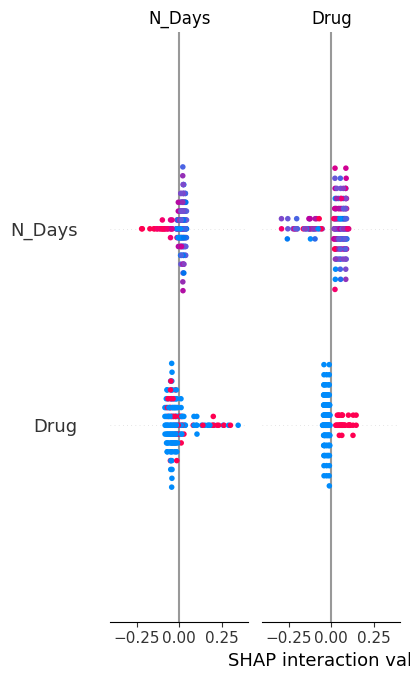

In [16]:
# =======================================================
# 8. Explainable AI (XAI)
# =======================================================
print("\nApplying Explainable AI (XAI) Methods...")

# LIME
print("\nLIME Explanation:")
# The LIME explainer needs the data as a numpy array
explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns,
    class_names=['No Cirrhosis', 'Cirrhosis'],
    mode='classification'
)
# We will explain the first instance from the test set
instance_to_explain = X_test.iloc[0]
exp = explainer.explain_instance(
    data_row=instance_to_explain.values,
    predict_fn=best_model.predict_proba,
    num_features=5
)
print("LIME Explanation for a single instance:")
# Removed the problematic line: print("Predicted Class (by local linear model):", exp.local_predictor.predict(instance_to_explain.values.reshape(1, -1)))
print("Original Model's Predicted Probability (Class 1):", best_model.predict_proba(instance_to_explain.values.reshape(1, -1))[0, 1])
print("Explanation breakdown (feature, weight):")
print(exp.as_list())

# Add visualization for LIME explanation
print("\nGenerating LIME visualization...")
# Try showing in notebook directly (may require specific notebook environments to render HTML)
exp.show_in_notebook(show_all=False)

# Save LIME explanation to an HTML file for persistent viewing
lime_html_path = "lime_explanation_instance_0.html"
exp.save_to_file(lime_html_path, show_all=False)
print(f"LIME explanation saved to {lime_html_path}")

# SHAP
print("\nSHAP Explanation:")
explainer_shap = shap.TreeExplainer(best_model)
shap_values = explainer_shap.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

print("SHAP Summary Plot: This plot shows the overall impact of features on the model's output.")
# Note: The plot will show in a pop-up window or notebook output
shap.summary_plot(shap_array, X_test, show=False)
plt.show()


PDP and ICE Plots:


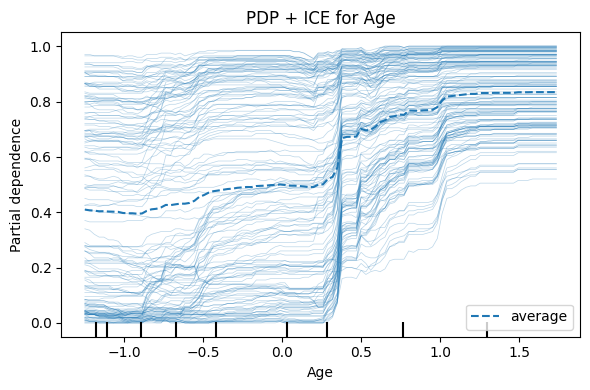

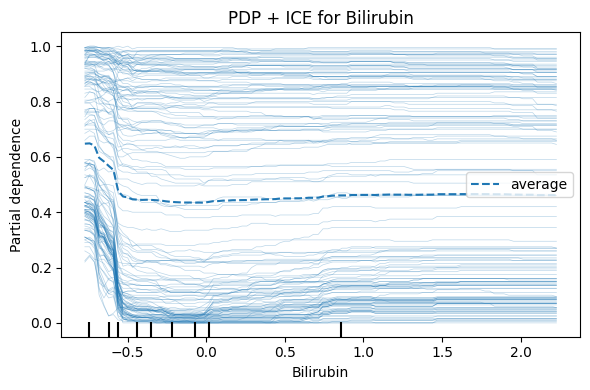

In [19]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

print("\nPDP and ICE Plots:")

# Select features
numerical_features_to_plot = ['Age', 'Bilirubin']

for feature in numerical_features_to_plot:
    fig, ax = plt.subplots(figsize=(6, 4))

    PartialDependenceDisplay.from_estimator(
        estimator=best_model,   # your trained model
        X=X_test,               # test data
        features=[feature],
        kind='both',            # 'average' = PDP, 'individual' = ICE, 'both' = both
        ax=ax
    )

    ax.set_title(f'PDP + ICE for {feature}')
    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

print("\nGenerating PDPs using scikit-learn's PartialDependenceDisplay...")

# Assuming 'best_model', 'X_train', and 'numerical_features_to_plot' are already defined
# The numerical_features_to_plot is ['Age', 'Bilirubin']

fig, ax = plt.subplots(figsize=(15, 6))
PartialDependenceDisplay.from_estimator(estimator=best_model,
                                         X=X_train,
                                         features=numerical_features_to_plot, # Use the list of features to plot
                                         target=1, # For binary classification, typically target=1 for the positive class
                                         feature_names=X_train.columns,
                                         ax=ax)
fig.suptitle('Partial Dependence Plots using scikit-learn')
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()